<a href="https://colab.research.google.com/github/summerof69/marketing-channel-attribution/blob/main/notebooks/attribution_2_attribution_models_explained_notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Marketing Channel Attribution, Part 2: first touch, last click (LC), linear and more

- Python notebook for **Part 2** of the series.
 - It regenerates the dummy journeys for **Kesari Threads** (fictional D2C ethnic-wear brand) and **TaskHarbor** (fictional B2B SaaS) and every data figure (except Figure 2 - how GA4 records a journey) in Part 1.
 - It applies six rule-based attribution models to one example journey and to 2,000 Kesari Threads orders, and regenerates every data figure and table in Part 2.
 - All companies and numbers are fictional and seeded, so every run reproduces the blog exactly.

## 1.Channels, journey generator and attribution models

- Every report uses the two funnel stages in Part 1
- **TOF** (top of funnel) is every touch up to the moment of intent, which is add to cart at Kesari Threads and the demo request at TaskHarbor
- **BOF** (bottom of funnel) is everything after it. The generator also gives each channel a journey role (opener, nurture or closer). That role only decides where a channel tends to appear in a simulated journey; it is never used in a report.
- TaskHarbor is simulated in USD and converted to INR at a fixed ₹80 per USD, so every amount in the series is in rupees. Each model takes one ordered journey and returns credit weights that add up to 1.

In [1]:
from __future__ import annotations

from collections import defaultdict

import numpy as np
import pandas as pd

# ---------------------------------------------------------------------------
# 1. Channel definitions
# ---------------------------------------------------------------------------
# Funnel stage used in every report, as defined in Part 1 of the series:
#   TOF (top of funnel)    = touches up to the moment of intent
#                            (add to cart at Kesari, the demo request at TaskHarbor)
#   BOF (bottom of funnel) = touches after it

D2C_CHANNELS = {
    "Instagram Ads":   "TOF",
    "YouTube":         "TOF",
    "Influencer":      "TOF",
    "Google Shopping": "TOF",
    "Email":           "BOF",   # mainly cart reminders after add to cart
    "Brand Search":    "BOF",
    "Direct":          "BOF",
}

B2B_CHANNELS = {
    "LinkedIn Ads":    "TOF",
    "Content / SEO":   "TOF",
    "Webinar":         "TOF",
    "Review Sites":    "TOF",
    "Email Nurture":   "TOF",   # nurture emails go to leads before the demo request
    "Brand Search":    "BOF",
    "Direct":          "BOF",
}

# Journey role, used only by the generator to place channels realistically:
# openers tend to start a journey, closers tend to end it, nurture sits between.
D2C_ROLES = {
    "Instagram Ads": "opener", "YouTube": "opener", "Influencer": "opener",
    "Google Shopping": "nurture", "Email": "nurture",
    "Brand Search": "closer", "Direct": "closer",
}
B2B_ROLES = {
    "LinkedIn Ads": "opener", "Content / SEO": "opener",
    "Webinar": "nurture", "Review Sites": "nurture", "Email Nurture": "nurture",
    "Brand Search": "closer", "Direct": "closer",
}

USD_TO_INR = 80  # TaskHarbor is simulated in USD, then reported in INR at a fixed rate

# Media / programme spend per channel for the period the journeys cover (illustrative).
# Direct has no spend. Brand Search is cheap because people already know you.
D2C_SPEND_INR = {
    "Instagram Ads": 900_000, "YouTube": 600_000, "Influencer": 500_000,
    "Google Shopping": 700_000, "Email": 100_000, "Brand Search": 200_000,
    "Direct": 0,
}
B2B_SPEND_INR = {  # annual programme spend for the same period as the 600 deals
    ch: usd * USD_TO_INR for ch, usd in {
        "LinkedIn Ads": 900_000, "Content / SEO": 400_000, "Webinar": 300_000,
        "Review Sites": 200_000, "Email Nurture": 80_000, "Brand Search": 150_000,
        "Direct": 0,
    }.items()
}


# ---------------------------------------------------------------------------
# 2. Journey generator
# ---------------------------------------------------------------------------
def _pick(rng, roles: dict, role: str, weights: dict | None = None) -> str:
    names = [c for c, r in roles.items() if r == role]
    p = np.array([weights.get(c, 1.0) if weights else 1.0 for c in names])
    return rng.choice(names, p=p / p.sum())


def generate_journeys(
    business: str = "d2c", n: int = 2000, seed: int = 42
) -> pd.DataFrame:
    """Return one row per touchpoint of converting journeys.

    Columns: journey_id, step, channel, stage, days_before_conversion, revenue
    Journeys follow a realistic shape: they usually *start* with opener
    channels (social, video, LinkedIn), pass through nurture channels and *end*
    on closers such as Brand Search or Direct. The `stage` column holds the
    TOF/BOF reporting stage. Revenue is INR for both companies.
    """
    rng = np.random.default_rng(seed)
    if business == "d2c":
        channels, roles = D2C_CHANNELS, D2C_ROLES
        mean_extra_touches, max_days = 2.0, 21
        tof_w = {"Instagram Ads": 3, "YouTube": 1.5, "Influencer": 1.5}
        mof_w = {"Google Shopping": 2, "Email": 1.5}
        bof_w = {"Brand Search": 1.3, "Direct": 1.0}
    elif business == "b2b":
        channels, roles = B2B_CHANNELS, B2B_ROLES
        mean_extra_touches, max_days = 6.0, 120
        tof_w = {"LinkedIn Ads": 2.5, "Content / SEO": 1.5}
        mof_w = {"Webinar": 1.2, "Review Sites": 1.0, "Email Nurture": 2.0}
        bof_w = {"Brand Search": 1.2, "Direct": 1.0}
    else:
        raise ValueError("business must be 'd2c' or 'b2b'")

    rows = []
    for j in range(n):
        n_touch = 1 + rng.poisson(mean_extra_touches)
        path = []
        for k in range(n_touch):
            pos = k / max(n_touch - 1, 1)  # 0 = first touch, 1 = last touch
            if n_touch == 1:
                stage_p = [0.25, 0.25, 0.50]  # single-touch: mostly intent
            elif k == 0:
                stage_p = [0.75, 0.20, 0.05]
            elif k == n_touch - 1:
                stage_p = [0.05, 0.20, 0.75]
            else:
                stage_p = [0.45 * (1 - pos) + 0.10,
                           0.55,
                           0.45 * pos - 0.10 + 0.0]
                stage_p = np.clip(stage_p, 0.02, None)
                stage_p = stage_p / stage_p.sum()
            role = rng.choice(["opener", "nurture", "closer"], p=stage_p)
            w = {"opener": tof_w, "nurture": mof_w, "closer": bof_w}[role]
            path.append(_pick(rng, roles, role, w))

        # days before conversion: first touch is oldest, last touch is day 0
        span = rng.uniform(0.2, 1.0) * max_days
        days = np.sort(rng.uniform(0, span, n_touch))[::-1]
        days[-1] = 0.0

        if business == "d2c":  # order value in INR
            revenue = float(np.round(rng.lognormal(np.log(2400), 0.45), -1))
        else:                  # first-year ARR, simulated in USD and reported in INR
            revenue = float(np.round(rng.lognormal(np.log(9000), 0.6), -2)) * USD_TO_INR

        for k, ch in enumerate(path):
            rows.append({
                "journey_id": f"{business.upper()}-{j:05d}",
                "step": k + 1,
                "channel": ch,
                "stage": channels[ch],
                "days_before_conversion": round(float(days[k]), 1),
                "revenue": revenue,
            })
    return pd.DataFrame(rows)


# ---------------------------------------------------------------------------
# 3. Attribution models
# ---------------------------------------------------------------------------
# Every model takes one journey (an ordered list of channels, plus optional
# days-before-conversion) and returns {channel: weight}, weights summing to 1.

def first_touch(path, days=None):
    return {path[0]: 1.0}


def last_click(path, days=None):
    """Last click (LC), also called last touch: the final touchpoint gets everything."""
    return {path[-1]: 1.0}


def last_non_direct(path, days=None, direct="Direct"):
    """Last Non-Direct Click: like last click (LC), but skips Direct visits.
    If the whole journey is Direct, Direct keeps the credit."""
    non_direct = [c for c in path if c != direct]
    return {(non_direct[-1] if non_direct else direct): 1.0}


def linear(path, days=None):
    w = defaultdict(float)
    for c in path:
        w[c] += 1.0 / len(path)
    return dict(w)


def position_based(path, days=None, first=0.4, last=0.4):
    """U-shaped: 40% first touch, 40% last touch, 20% spread over the middle."""
    n = len(path)
    if n == 1:
        return {path[0]: 1.0}
    if n == 2:
        w = defaultdict(float)
        w[path[0]] += 0.5
        w[path[1]] += 0.5
        return dict(w)
    w = defaultdict(float)
    w[path[0]] += first
    w[path[-1]] += last
    middle = (1 - first - last) / (n - 2)
    for c in path[1:-1]:
        w[c] += middle
    return dict(w)


def time_decay(path, days, half_life=7.0):
    """Touches closer to conversion get more credit: weight = 2^(-days/half_life)."""
    raw = np.power(2.0, -np.asarray(days, dtype=float) / half_life)
    raw = raw / raw.sum()
    w = defaultdict(float)
    for c, r in zip(path, raw):
        w[c] += float(r)
    return dict(w)


MODELS = {
    "First touch": first_touch,
    "Last click (LC)": last_click,
    "Last non-direct": last_non_direct,
    "Linear": linear,
    "Position-based": position_based,
    "Time decay": time_decay,
}


def attribute(df: pd.DataFrame, model, value: str = "revenue") -> pd.Series:
    """Apply one model to every journey. Returns attributed value by channel.
    value='revenue' distributes money; value='conversions' distributes counts."""
    credit = defaultdict(float)
    for _, g in df.sort_values(["journey_id", "step"]).groupby("journey_id"):
        path = g["channel"].tolist()
        days = g["days_before_conversion"].tolist()
        amount = 1.0 if value == "conversions" else g["revenue"].iloc[0]
        for ch, w in model(path, days).items():
            credit[ch] += w * amount
    return pd.Series(credit)


def compare_models(df: pd.DataFrame, value: str = "revenue") -> pd.DataFrame:
    """Attributed value by channel (rows) for every model (columns)."""
    out = pd.DataFrame({name: attribute(df, fn, value) for name, fn in MODELS.items()})
    return out.fillna(0.0)


def share_table(table: pd.DataFrame) -> pd.DataFrame:
    return (table / table.sum() * 100).round(1)


def stage_share(table: pd.DataFrame, channels: dict) -> pd.DataFrame:
    """Share of credit going to TOF and BOF channels under each model."""
    st = table.groupby(table.index.map(channels)).sum()
    return (st / st.sum() * 100).round(1).reindex(["TOF", "BOF"])


def roas_table(table: pd.DataFrame, spend: dict) -> pd.DataFrame:
    """Attributed revenue / spend for each paid channel under each model."""
    s = pd.Series(spend)
    s = s[s > 0]
    return table.loc[s.index].div(s, axis=0).round(2)


def zero_credit_share(df: pd.DataFrame) -> float:
    """% of all touchpoints that get no credit under a single-touch model (LC or LNDC)."""
    return round(float((1 - df["journey_id"].nunique() / len(df)) * 100), 1)


def journey_summary(df: pd.DataFrame) -> dict:
    lengths = df.groupby("journey_id")["step"].max()
    return {
        "journeys": int(lengths.size),
        "mean_touches": round(float(lengths.mean()), 1),
        "median_touches": float(lengths.median()),
        "single_touch_pct": round(float((lengths == 1).mean() * 100), 1),
        "zero_credit_touch_pct_lc": zero_credit_share(df),
        "revenue_total": float(df.groupby("journey_id")["revenue"].first().sum()),
    }


# ---------------------------------------------------------------------------
# 4. A worked single journey (used in Part 2)
# ---------------------------------------------------------------------------
EXAMPLE_PATH = ["Instagram Ads", "Email", "Google Shopping", "Direct"]
EXAMPLE_DAYS = [14, 6, 2, 0]
EXAMPLE_REVENUE = 3000  # INR


def example_journey_split() -> pd.DataFrame:
    rows = {}
    for name, fn in MODELS.items():
        rows[name] = {ch: w * EXAMPLE_REVENUE for ch, w in fn(EXAMPLE_PATH, EXAMPLE_DAYS).items()}
    return pd.DataFrame(rows).T.reindex(columns=EXAMPLE_PATH).fillna(0).round(0)

## 2. Generate the dummy data and save it as CSV

One row per touchpoint of a converting journey.

---------------------------------------------------------------------------
Column guide: one row = one touchpoint in a journey that ended in a conversion
---------------------------------------------------------------------------
- journey_id             : ID of one customer's path to a single conversion.
                         D2C-xxxxx = a Kesari Threads order, B2B-xxxxx = a TaskHarbor deal.
                         Every row with the same journey_id belongs to the same journey.
- step                   : order of the touchpoint within its journey.
                         1 = first touch; the highest step = last touch before converting.
- channel                : the source the touchpoint came from
                         (e.g. Instagram Ads, Email, Google Shopping, Brand Search, Direct).
- stage                  : funnel stage. TOF = up to add to cart (Kesari) or the demo request
                         (TaskHarbor); BOF = after it.
- days_before_conversion : how many days before the conversion the touch happened.
                         The last touch is always 0.
- revenue                : value of the whole conversion in INR (Kesari order value, or
                         TaskHarbor first-year ARR at ₹80/USD). It repeats on every row of
                         a journey, so take one value per journey_id before summing.
- company                : Kesari Threads (fictional D2C brand) or TaskHarbor (fictional B2B SaaS).

In [2]:
d2c = generate_journeys("d2c", n=2000, seed=42)
b2b = generate_journeys("b2b", n=600, seed=7)
data = pd.concat([d2c.assign(company="Kesari Threads"), b2b.assign(company="TaskHarbor")])
data.to_csv("attribution-2-attribution-models-explained-data.csv", index=False)
data.head(8)

,journey_id,step,channel,stage,days_before_conversion,revenue,company
0,D2C-00000,1,Direct,BOF,6.6,1770.0,Kesari Threads
1,D2C-00000,2,Google Shopping,TOF,6.1,1770.0,Kesari Threads
2,D2C-00000,3,Google Shopping,TOF,5.1,1770.0,Kesari Threads
3,D2C-00000,4,Direct,BOF,4.4,1770.0,Kesari Threads
4,D2C-00000,5,Brand Search,BOF,0.0,1770.0,Kesari Threads
5,D2C-00001,1,Instagram Ads,TOF,5.8,3220.0,Kesari Threads
6,D2C-00001,2,YouTube,TOF,2.7,3220.0,Kesari Threads
7,D2C-00001,3,Email,BOF,2.3,3220.0,Kesari Threads


### 2.1Journey summary for both companies

`zero_credit_touch_pct_lc` is the share of touchpoints that get no credit under a single-touch model such as last click (LC) or LNDC.

In [3]:
pd.DataFrame({'Kesari Threads': journey_summary(d2c), 'TaskHarbor': journey_summary(b2b)})

,Kesari Threads,TaskHarbor
journeys,2000.0,600.0
mean_touches,3.0,7.1
median_touches,3.0,7.0
single_touch_pct,13.6,0.2
zero_credit_touch_pct_lc,66.8,85.9
revenue_total,5338320.0,522584000.0


## 3.Plot settings

In [4]:
|import os
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from matplotlib.patches import FancyBboxPatch

OUT = "."  # figures are saved next to the notebook
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "font.size": 12,
    "axes.titlesize": 15, "axes.titleweight": "bold", "axes.labelsize": 12,
    "axes.spines.top": False, "axes.spines.right": False,
})
STAGE_COL = {"TOF": "#3b82f6", "BOF": "#ef4444"}
TOUCH_COL = ["#3b82f6", "#a855f7", "#f59e0b", "#ef4444"]  # Instagram, Email, Google Shopping, Direct
LC = "Last click (LC)"
MODEL_ORDER = list(MODELS.keys())
FUNNEL_ORDER = ["Influencer", "Instagram Ads", "YouTube", "Google Shopping", "Email",
                "LinkedIn Ads", "Content / SEO", "Review Sites", "Webinar", "Email Nurture",
                "Brand Search", "Direct"]
rev_d2c = compare_models(d2c, "revenue")
rev_b2b = compare_models(b2b, "revenue")


def save(fig, name):
    """Save the figure next to the notebook and show it."""
    fig.savefig(os.path.join(OUT, name), dpi=150, bbox_inches="tight")
    display(fig)
    plt.close(fig)

## 4.1Figure 1: one ₹3,000 order, six models

In [5]:
example_journey_split().reindex(MODEL_ORDER)

,Instagram Ads,Email,Google Shopping,Direct
First touch,3000.0,0.0,0.0,0.0
Last click (LC),0.0,0.0,0.0,3000.0
Last non-direct,0.0,0.0,3000.0,0.0
Linear,750.0,750.0,750.0,750.0
Position-based,1200.0,300.0,300.0,1200.0
Time decay,286.0,632.0,938.0,1144.0


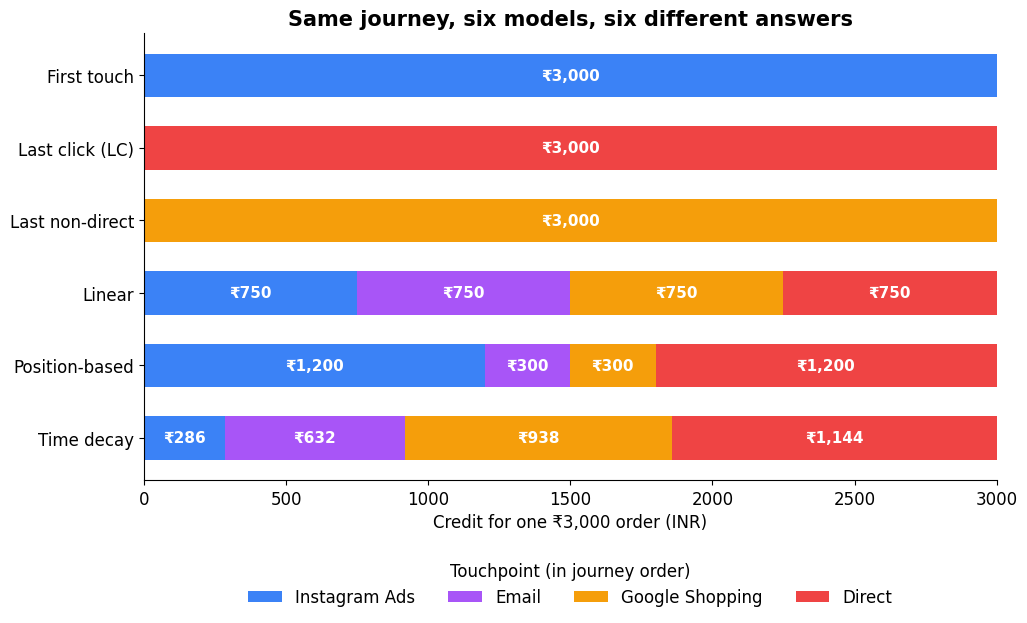

In [6]:
def fig_example_split():
    """Part 2, Figure 1: the Rs 3,000 order under all six models."""
    t = example_journey_split().reindex(MODEL_ORDER)
    fig, ax = plt.subplots(figsize=(11, 5.8))
    left = np.zeros(len(t))
    for c, col in zip(EXAMPLE_PATH, TOUCH_COL):
        vals = t[c].values
        ax.barh(t.index, vals, left=left, color=col, label=c, height=0.6)
        for i, (v, l) in enumerate(zip(vals, left)):
            if v >= 250:
                ax.text(l + v / 2, i, f"₹{v:,.0f}", ha="center", va="center", color="white", fontsize=11, weight="bold")
        left += vals
    ax.invert_yaxis()
    ax.set_xlabel("Credit for one ₹3,000 order (INR)")
    ax.set_xlim(0, EXAMPLE_REVENUE)
    ax.legend(title="Touchpoint (in journey order)", ncol=4, loc="upper center",
              bbox_to_anchor=(0.5, -0.15), frameon=False)
    ax.set_title("Same journey, six models, six different answers")
    save(fig, "02-example-journey-credit-split-lc.png")


fig_example_split()

## Position-based with your own percentages

The 40/20/40 split is a convention. Any split works as long as it adds up to 100%. The labels below read first / middle / last.

In [ ]:
splits = {'40/20/40': (0.4, 0.4), '30/40/30': (0.3, 0.3), '50/0/50': (0.5, 0.5), '60/20/20': (0.6, 0.2)}
pd.DataFrame({label: {ch: w * EXAMPLE_REVENUE for ch, w in position_based(EXAMPLE_PATH, first=f, last=l).items()}
              for label, (f, l) in splits.items()}).T[EXAMPLE_PATH].round(0)

,Instagram Ads,Email,Google Shopping,Direct
40/20/40,1200.0,300.0,300.0,1200.0
30/40/30,900.0,600.0,600.0,900.0
50/0/50,1500.0,0.0,0.0,1500.0
60/20/20,1800.0,300.0,300.0,600.0


## 4.2Time decay: the worked example

`weight = 2 ** (-days before conversion / half-life)`, then each weight is divided by the total.

In [7]:
half_life = 7
raw = pd.Series([2 ** (-d / half_life) for d in EXAMPLE_DAYS], index=EXAMPLE_PATH)
pd.DataFrame({'days_before': EXAMPLE_DAYS, 'days / half-life': [round(d / half_life, 2) for d in EXAMPLE_DAYS],
              'raw_weight': raw.round(3), 'share_%': (raw / raw.sum() * 100).round(1),
              'credit_inr': (raw / raw.sum() * EXAMPLE_REVENUE).round(0)}, index=EXAMPLE_PATH)

,days_before,days / half-life,raw_weight,share_%,credit_inr
Instagram Ads,14,2.00,0.250,9.5,286.0
Email,6,0.86,0.552,21.1,632.0
Google Shopping,2,0.29,0.820,31.3,938.0
Direct,0,0.00,1.000,38.1,1144.0


### How the half-life moves the credit

The same ₹3,000 order under four half-lives (rounded to the nearest rupee, so a row can be off by ₹1).

In [8]:
pd.DataFrame({f'{hl} days': {ch: w * EXAMPLE_REVENUE for ch, w in time_decay(EXAMPLE_PATH, EXAMPLE_DAYS, half_life=hl).items()}
              for hl in [3, 7, 14, 30]}).T[EXAMPLE_PATH].round(0)

,Instagram Ads,Email,Google Shopping,Direct
3 days,62.0,391.0,985.0,1563.0
7 days,286.0,632.0,938.0,1144.0
14 days,476.0,708.0,863.0,953.0
30 days,612.0,736.0,807.0,845.0


## 4.3Figure 3: share of Kesari revenue by channel and model

TOF channels sit above the line and BOF channels below it.

In [9]:
share_table(rev_d2c)[MODEL_ORDER].loc[sorted(rev_d2c.index, key=FUNNEL_ORDER.index)]

,First touch,Last click (LC),Last non-direct,Linear,Position-based,Time decay
Influencer,16.2,1.7,4.4,8.4,8.7,6.3
Instagram Ads,32.1,3.6,9.0,17.1,17.5,12.7
YouTube,18.0,2.1,4.9,9.4,9.8,7.1
Google Shopping,12.2,11.9,19.2,17.7,14.5,17.0
Email,10.1,9.7,16.0,14.1,11.8,13.5
Brand Search,6.5,41.4,43.4,19.3,21.9,25.2
Direct,5.0,29.6,3.0,14.0,15.9,18.3


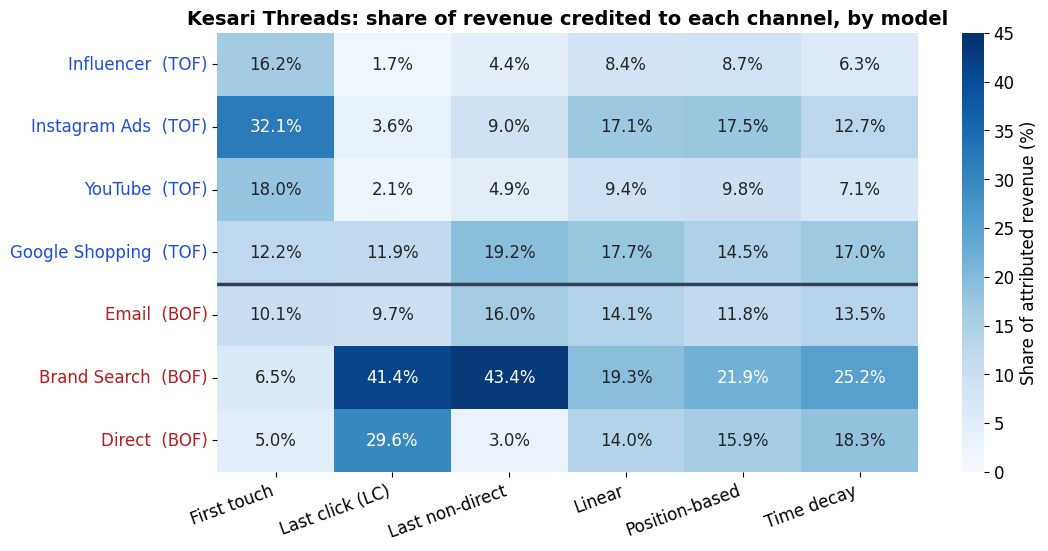

In [10]:
def fig_heatmap():
    """Part 2, Figure 3: Kesari revenue share by channel and model, TOF above the line, BOF below."""
    share = share_table(rev_d2c)[MODEL_ORDER]
    share = share.loc[sorted(share.index, key=FUNNEL_ORDER.index)]
    n_tof = sum(D2C_CHANNELS[c] == "TOF" for c in share.index)
    fig, ax = plt.subplots(figsize=(11.3, 5.7))
    sns.heatmap(share.values, annot=share.map(lambda v: f"{v:.1f}%").values, fmt="", cmap="Blues",
                vmin=0, vmax=45, xticklabels=share.columns, ax=ax, annot_kws={"fontsize": 12},
                yticklabels=[f"{c}  ({D2C_CHANNELS[c]})" for c in share.index],
                cbar_kws={"label": "Share of attributed revenue (%)"})
    ax.axhline(n_tof, color="#334155", linewidth=2.5)
    for t, c in zip(ax.get_yticklabels(), share.index):
        t.set_color("#1d4ed8" if D2C_CHANNELS[c] == "TOF" else "#b91c1c")
    ax.set_title("Kesari Threads: share of revenue credited to each channel, by model", fontsize=14)
    plt.setp(ax.get_xticklabels(), rotation=20, ha="right")
    ax.tick_params(axis="y", rotation=0)
    save(fig, "02-d2c-credit-heatmap-by-model-lc.png")


fig_heatmap()

## 4.4Figure 4: which rule-based model fits the decision

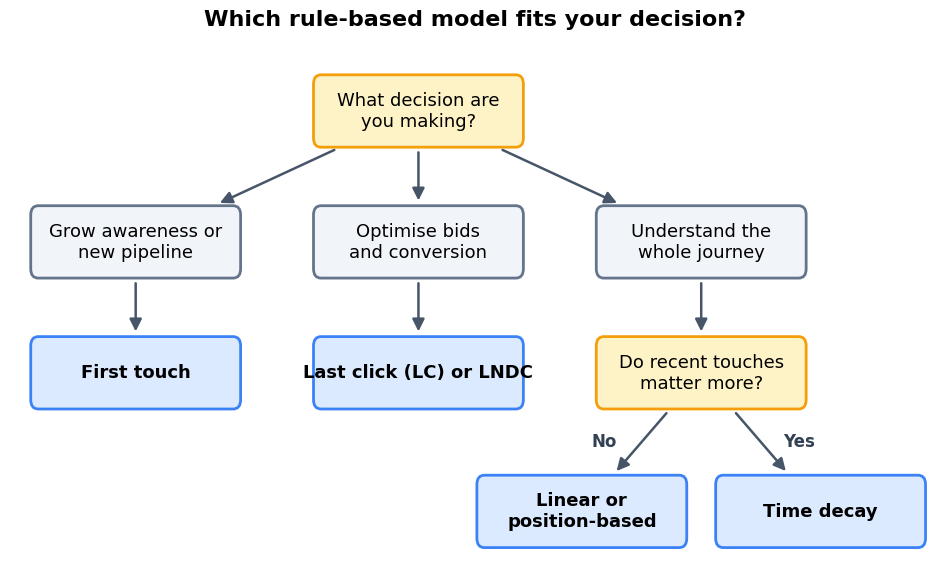

In [ ]:
def draw_boxes(ax, nodes, w, h, styles, fontsize=13):
    """Rounded boxes keyed by name: nodes = {key: (x, y, text, style)}. Returns the patches."""
    patches = {}
    for key, (x, y, text, kind) in nodes.items():
        fill, edge, bold = styles[kind]
        p = FancyBboxPatch((x - w / 2, y - h / 2), w, h, boxstyle="round,pad=0.02,rounding_size=0.12",
                           facecolor=fill, edgecolor=edge, linewidth=2, zorder=3)
        ax.add_patch(p)
        ax.text(x, y, text, ha="center", va="center", fontsize=fontsize, zorder=4,
                fontweight="bold" if bold else "normal")
        patches[key] = p
    return patches


def fig_model_flowchart():
    """Part 2, Figure 4: which rule-based model fits the decision."""
    nodes = {
        "A": (6.5, 6.4, "What decision are\nyou making?", "decision"),
        "B": (2.0, 4.7, "Grow awareness or\nnew pipeline", "goal"),
        "C": (6.5, 4.7, "Optimise bids\nand conversion", "goal"),
        "D": (11.0, 4.7, "Understand the\nwhole journey", "goal"),
        "E": (2.0, 3.0, "First touch", "model"),
        "F": (6.5, 3.0, "Last click (LC) or LNDC", "model"),
        "G": (11.0, 3.0, "Do recent touches\nmatter more?", "decision"),
        "H": (9.1, 1.2, "Linear or\nposition-based", "model"),
        "I": (12.9, 1.2, "Time decay", "model"),
    }
    styles = {"decision": ("#fef3c7", "#f59e0b", False), "goal": ("#f1f5f9", "#64748b", False),
              "model": ("#dbeafe", "#3b82f6", True)}
    fig, ax = plt.subplots(figsize=(12, 7))
    ax.set_xlim(0, 14.8); ax.set_ylim(0.4, 7.4); ax.axis("off")
    boxes = draw_boxes(ax, nodes, 3.3, 0.9, styles)
    for a, b, label in [("A", "B", None), ("A", "C", None), ("A", "D", None), ("B", "E", None),
                        ("C", "F", None), ("D", "G", None), ("G", "H", "No"), ("G", "I", "Yes")]:
        ax.annotate("", xy=nodes[b][:2], xytext=nodes[a][:2], zorder=5,
                    arrowprops=dict(arrowstyle="-|>", color="#475569", lw=1.8, mutation_scale=18,
                                    patchA=boxes[a], patchB=boxes[b], shrinkA=3, shrinkB=3))
        if label:
            xa, ya = nodes[a][:2]; xb, yb = nodes[b][:2]
            ax.text((xa + xb) / 2 + (-0.6 if xb < xa else 0.6), (ya + yb) / 2, label, ha="center",
                    va="center", fontsize=12, color="#334155", fontweight="bold")
    ax.set_title("Which rule-based model fits your decision?", fontsize=16)
    save(fig, "02-model-choice-flowchart-lc.png")


fig_model_flowchart()